Jagmeet Singh Data Mining 1 Assignment 2

https://github.com/singhj95/DataMiningI

#1. Data Preparation

In [83]:
import matplotlib.pyplot as plt
import skimage as ski
from skimage import data, exposure
from skimage.color import rgb2gray
from skimage import filters
from skimage.feature import hog
import numpy as np
import pandas as pd
from sklearn import datasets
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import pairwise_distances
from sklearn.metrics.pairwise import pairwise_kernels
from sklearn.preprocessing import StandardScaler
import seaborn as sns

In [84]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/DataMining/content/Coffee Bean.csv')
beans_training = df[df['data set'] == 'train']
beans_testing = df[df['data set'] == 'test']
training_images = []
testing_images = []
training_sobel = []
testing_sobel = []
training_hist = []
testing_hist = []
training_hist_centers = []
testing_hist_centers = []
training_labels = beans_training['labels']
testing_labels = beans_testing['labels']
bean_classes = beans_training['labels'].unique()

In [85]:
def angle(dx, dy):
#Calculate the angles between horizontal and vertical operators.
  return np.mod(np.arctan2(dy, dx), np.pi)

def bean_sobel(bean):
  return angle(filters.sobel_h(bean), filters.sobel_v(bean))

def bean_histogram(bean):
  return exposure.histogram(bean, 36)

In [86]:
for index, row in beans_training.iterrows():
  bean = ski.io.imread('/content/drive/MyDrive/Colab Notebooks/DataMining/content/' + row['filepaths'])
  training_images.append(bean)
  bean = rgb2gray(bean)
  sobel_bean = bean_sobel(bean)
  training_sobel.append(sobel_bean)
  histogram_bean, histogram_bean_center = bean_histogram(sobel_bean)
  training_hist.append(histogram_bean)
  training_hist_centers.append(histogram_bean_center)
  training_histograms_unnormal = np.array(training_hist)
  training_histograms = training_histograms_unnormal / training_histograms_unnormal.sum(axis=1, keepdims=True)

In [87]:
for index, row in beans_testing.iterrows():
  bean = ski.io.imread('/content/drive/MyDrive/Colab Notebooks/DataMining/content/' + row['filepaths'])
  testing_images.append(bean)
  bean = rgb2gray(bean)
  sobel_bean = bean_sobel(bean)
  testing_sobel.append(sobel_bean)
  histogram_bean, histogram_bean_center = bean_histogram(sobel_bean)
  testing_hist.append(histogram_bean)
  testing_hist_centers.append(histogram_bean_center)
  testing_histograms_unnormal = np.array(testing_hist)
  testing_histograms = testing_histograms_unnormal / testing_histograms_unnormal.sum(axis=1, keepdims=True)

In [88]:
print(f"Number of Training Histograms: {training_histograms.shape}")
print(f"Number of Testing Histograms: {testing_histograms.shape}")
print(f"Number of Classes: {bean_classes.size}")
print(f"Number of Training Images by Class: {beans_training['labels'].value_counts()}")
print(f"Number of Testing Images Classes: {beans_testing['labels'].value_counts()}")

Number of Training Histograms: (1200, 36)
Number of Testing Histograms: (400, 36)
Number of Classes: 4
Number of Training Images by Class: labels
Dark      300
Green     300
Light     300
Medium    300
Name: count, dtype: int64
Number of Testing Images Classes: labels
Dark      100
Green     100
Light     100
Medium    100
Name: count, dtype: int64


In [89]:
#To standardize the data, I used scikit-learn's StandardScaler()
training_scaler = StandardScaler()
training_scaled = training_scaler.fit_transform(training_histograms)
testing_scaled = training_scaler.transform(testing_histograms)

You cannot introduce any outside information to the testing dataset. We want to use the testing dataset to be able to predict the features of the data. If it is trained on that data, it will skew the model to be able to more accurately predict the testing data, rendering the idea of a testing dataset useless as we are trying to create a prediction model we can use on any dataset.

# 2. Performance Comparison

In [90]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

#Naive Bayes
#Decision Tree
#Random Forest Classifier

pipelines = {
    "Gaussian Naive Bayes": Pipeline([
        ('scaler', StandardScaler()),
        ('model', GaussianNB())
    ]),
    "Decision Tree": Pipeline([
        ('scaler', StandardScaler()),
        ('model', DecisionTreeClassifier(max_depth=10, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ('scaler', StandardScaler()),
        ('model', RandomForestClassifier(random_state=42))
    ])
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("--- Stratified 5-Fold Cross-Validation Results ---\n")

for name, pipeline in pipelines.items():
    scores = cross_val_score(pipeline, training_histograms, training_labels, cv=skf, scoring='accuracy', n_jobs=-1)

    print(f"=== {name} ===")
    print(f"Fold Scores: {np.round(scores, 4)}")
    print(f"Mean Accuracy: {np.mean(scores):.4f}")
    print(f"Standard Dev:  {np.std(scores):.4f}\n")

--- Stratified 5-Fold Cross-Validation Results ---

=== Gaussian Naive Bayes ===
Fold Scores: [0.4167 0.3958 0.3917 0.4042 0.4333]
Mean Accuracy: 0.4083
Standard Dev:  0.0151

=== Decision Tree ===
Fold Scores: [0.4208 0.4083 0.3917 0.4208 0.4   ]
Mean Accuracy: 0.4083
Standard Dev:  0.0115

=== Random Forest ===
Fold Scores: [0.475  0.5333 0.5125 0.5    0.5375]
Mean Accuracy: 0.5117
Standard Dev:  0.0229



Based on only the cross-validation results, the best classifier would be the Random Forest. It has the highest accuracy across the 5 fold scores, as seen by the Mean Accuracy. The standard deviation is slightly higher, but can be overlooked because the accuracy scores are much better than the other classifiers.

In [91]:
final_naive_bayes = Pipeline([
    ('scaler', StandardScaler()),
    ('model', GaussianNB())
])

final_decision_tree = Pipeline([
    ('scaler', StandardScaler()),
    ('model', DecisionTreeClassifier(max_depth=10, random_state=42))
])

final_random_forest = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier(random_state=42))
])

final_naive_bayes.fit(training_histograms, training_labels)
final_decision_tree.fit(training_histograms, training_labels)
final_random_forest.fit(training_histograms, training_labels)

trained_classifiers = {
    "Naive Bayes": final_naive_bayes,
    "Decision Tree": final_decision_tree,
    "Random Forest": final_random_forest
}

--- Final Evaluation Across All Classifiers ---

=== Naive Bayes ===
  Test Accuracy: 0.4450
  F1 Score: 0.4397



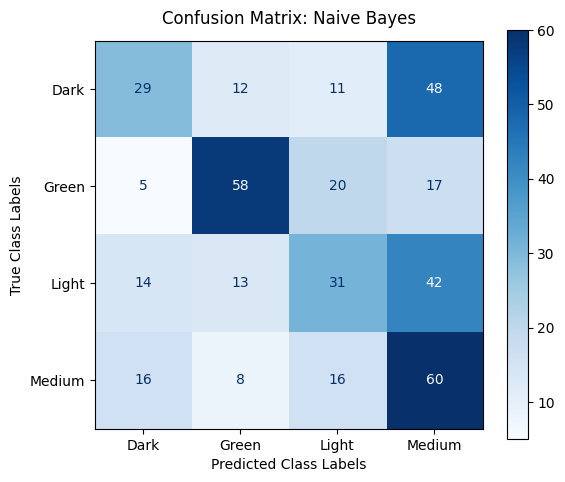

=== Decision Tree ===
  Test Accuracy: 0.8150
  F1 Score: 0.8158



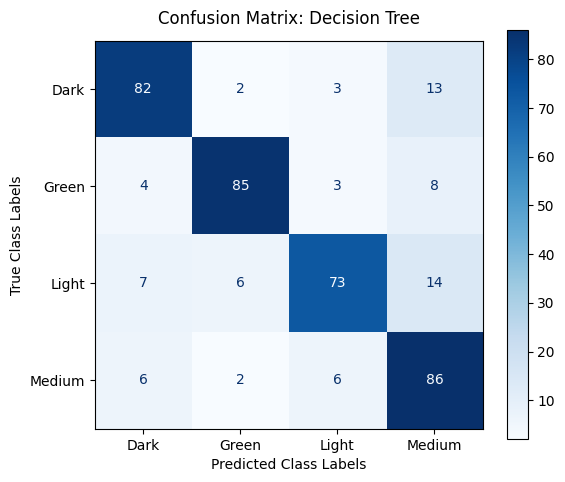

=== Random Forest ===
  Test Accuracy: 1.0000
  F1 Score: 1.0000



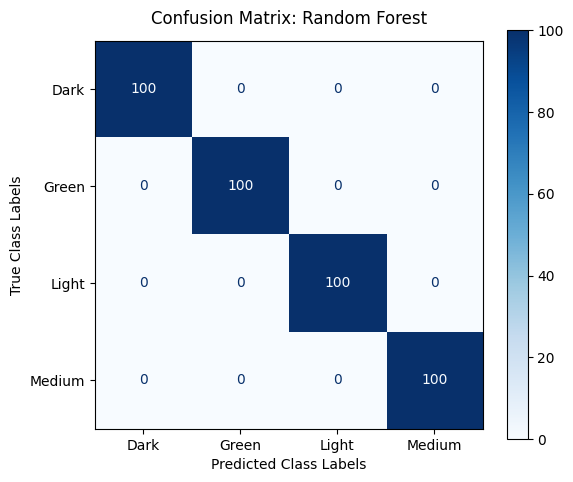

In [92]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay, accuracy_score, f1_score

print("--- Final Evaluation Across All Classifiers ---\n")

naive_bayes_pred = trained_classifiers["Naive Bayes"].predict(testing_histograms)
decision_pred = trained_classifiers["Decision Tree"].predict(testing_histograms)
random_forest_pred = trained_classifiers["Random Forest"].predict(testing_histograms)

naive_bayes_test_accuracy = accuracy_score(testing_labels, naive_bayes_pred)
decision_test_accuracy = accuracy_score(testing_labels, decision_pred)
random_forest_test_accuracy = accuracy_score(testing_labels, random_forest_pred)

naive_bayes_macro_f1 = f1_score(testing_labels, naive_bayes_pred, average='macro')
decision_macro_f1 = f1_score(testing_labels, decision_pred, average='macro')
random_forest_macro_f1 = f1_score(testing_labels, random_forest_pred, average='macro')

print(f"=== Naive Bayes ===")
print(f"  Test Accuracy: {naive_bayes_test_accuracy:.4f}")
print(f"  F1 Score: {naive_bayes_macro_f1:.4f}\n")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_true=testing_labels,
    y_pred=naive_bayes_pred,
    display_labels=bean_classes,
    cmap=plt.cm.Blues,
    ax=ax
)

plt.title(f'Confusion Matrix: Naive Bayes', fontsize=12, pad=12)
plt.xlabel('Predicted Class Labels', fontsize=10)
plt.ylabel('True Class Labels', fontsize=10)
plt.tight_layout()
plt.show()

print(f"=== Decision Tree ===")
print(f"  Test Accuracy: {decision_test_accuracy:.4f}")
print(f"  F1 Score: {decision_macro_f1:.4f}\n")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_true=testing_labels,
    y_pred=decision_pred,
    display_labels=bean_classes,
    cmap=plt.cm.Blues,
    ax=ax
)

plt.title(f'Confusion Matrix: Decision Tree', fontsize=12, pad=12)
plt.xlabel('Predicted Class Labels', fontsize=10)
plt.ylabel('True Class Labels', fontsize=10)
plt.tight_layout()

plt.show()

print(f"=== Random Forest ===")
print(f"  Test Accuracy: {random_forest_test_accuracy:.4f}")
print(f"  F1 Score: {random_forest_macro_f1:.4f}\n")

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_true=testing_labels,
    y_pred=random_forest_pred,
    display_labels=bean_classes,
    cmap=plt.cm.Blues,
    ax=ax
)

plt.title(f'Confusion Matrix: Random Forest', fontsize=12, pad=12)
plt.xlabel('Predicted Class Labels', fontsize=10)
plt.ylabel('True Class Labels', fontsize=10)
plt.tight_layout()

plt.show()

The class "Medium" was most often confused to be another class. In the Naive Bayes, we see that it was confused for the class "Dark" 48 times, and confused as the class "Light" 42 times. For the Decision Tree, it was confused 13 for "Dark" and 14 for "Light".

This means that the "Medium" class looks visually similar to the "Light" and "Dark" classes. Because we are using the edge histograms, the similarities are in the vector edges of each bean.

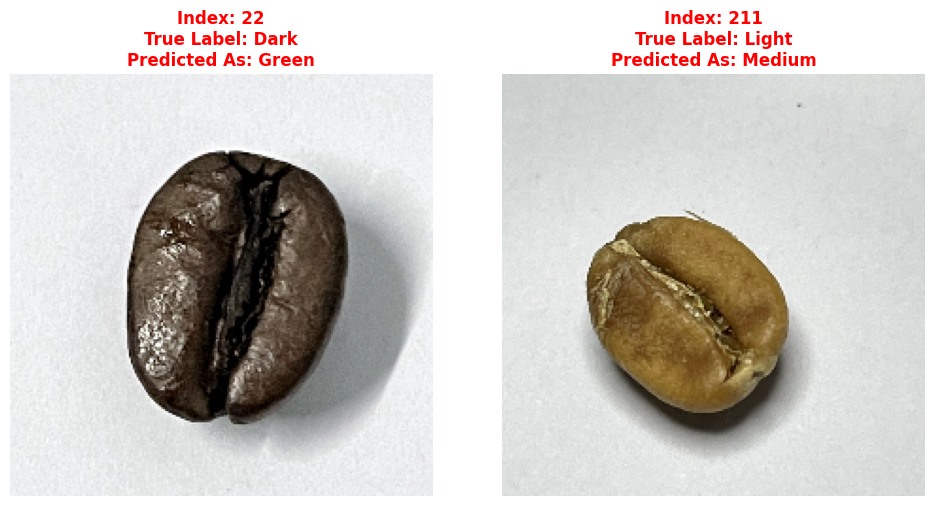

In [93]:
naive_misclassified= np.where(naive_bayes_pred != testing_labels)[0]

naive_misclassified_idx_1 = np.random.choice(naive_misclassified)
#to make sure they aren't the same random choice of misclassified images:
naive_misclassified_idx_2 = naive_misclassified_idx_1
while (naive_misclassified_idx_2 == naive_misclassified_idx_1):
  naive_misclassified_idx_2 = np.random.choice(naive_misclassified)

naive_true_label_1 = testing_labels[naive_misclassified_idx_1 + 1200]
naive_true_label_2 = testing_labels[naive_misclassified_idx_2 + 1200]

naive_pred_label_1 = naive_bayes_pred[naive_misclassified_idx_1]
naive_pred_label_2 = naive_bayes_pred[naive_misclassified_idx_2]

naive_misclassified_image_1 = testing_images[naive_misclassified_idx_1]
naive_misclassified_image_2 = testing_images[naive_misclassified_idx_2]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(naive_misclassified_image_1)
axes[1].imshow(naive_misclassified_image_2)

axes[0].set_title(f"Index: {naive_misclassified_idx_1}\nTrue Label: {naive_true_label_1}\nPredicted As: {naive_pred_label_1}", color='red', fontsize=12, fontweight='bold')
axes[1].set_title(f"Index: {naive_misclassified_idx_2}\nTrue Label: {naive_true_label_2}\nPredicted As: {naive_pred_label_2}", color='red', fontsize=12, fontweight='bold')

axes[0].axis('off')
axes[1].axis('off')

plt.tight_layout()
plt.show()

This dataset is interesting as most of the defining characteristics of the beans relate to the color. When looking at the black and white images, the beans do look mainly identical, so getting certain beans confused is expected.

# 3. Model Selection and Model Complexity

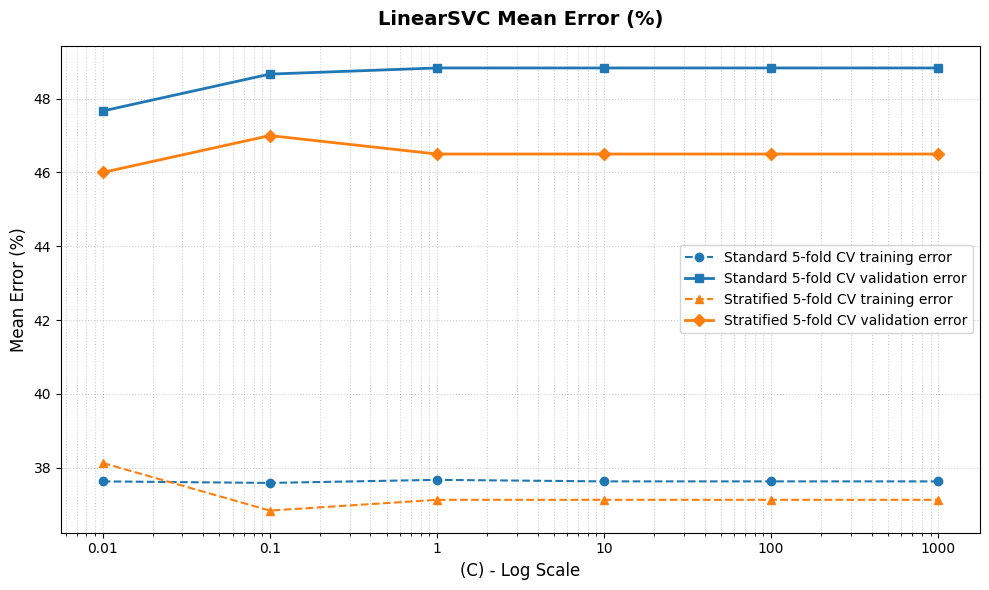

In [94]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.svm import LinearSVC

two_class_array = np.array(training_histograms)
two_class_array = np.concatenate((two_class_array[:300], two_class_array[-300:]), axis=0)

two_class_labels = np.array(training_labels)
two_class_labels = np.concatenate((two_class_labels[:300], two_class_labels[-300:]), axis=0)

c_values = [0.01, 0.1, 1, 10, 100, 1000]

standard_cv = KFold(n_splits=5, shuffle=True, random_state=42)
stratified_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

std_train_errors = []
std_val_errors = []
strat_train_errors = []
strat_val_errors = []

for cv_name, cv_splitter in [("Standard", standard_cv), ("Stratified", stratified_cv)]:
  for C in c_values:
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('model', LinearSVC(C=C, random_state=42))
        ])

        cv_results = cross_validate(
            pipeline, two_class_array, two_class_labels,
            cv=cv_splitter,
            scoring='accuracy',
            return_train_score=True
        )

        mean_train_error = (1.0 - np.mean(cv_results['train_score'])) * 100.0
        mean_val_error = (1.0 - np.mean(cv_results['test_score'])) * 100.0

        if cv_name == "Standard":
            std_train_errors.append(mean_train_error)
            std_val_errors.append(mean_val_error)
        else:
            strat_train_errors.append(mean_train_error)
            strat_val_errors.append(mean_val_error)

plt.figure(figsize=(10, 6))

plt.plot(c_values, std_train_errors, label='Standard 5-fold CV training error',
         color='#1f77b4', linestyle='--', marker='o', linewidth=1.5)
plt.plot(c_values, std_val_errors, label='Standard 5-fold CV validation error',
         color='#1f77b4', linestyle='-', marker='s', linewidth=2.0)

plt.plot(c_values, strat_train_errors, label='Stratified 5-fold CV training error',
         color='#ff7f0e', linestyle='--', marker='^', linewidth=1.5)
plt.plot(c_values, strat_val_errors, label='Stratified 5-fold CV validation error',
         color='#ff7f0e', linestyle='-', marker='D', linewidth=2.0)

plt.xscale('log')
plt.xticks(c_values, labels=[str(c) for c in c_values])
plt.grid(True, which="both", linestyle=":", alpha=0.6)

plt.title('LinearSVC Mean Error (%)', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('(C) - Log Scale', fontsize=12)
plt.ylabel('Mean Error (%)', fontsize=12)
plt.legend(fontsize=10, loc='best', frameon=True, shadow=False)

plt.tight_layout()
plt.show()

In [95]:
best_std_idx = np.argmin(std_val_errors)
best_strat_idx = np.argmin(strat_val_errors)

best_c_standard = c_values[best_std_idx]
best_c_stratified = c_values[best_strat_idx]

print(f"Standard 5-Fold CV:")
print(f"  - Lowest Validation Error: {std_val_errors[best_std_idx]:.2f}%")
print(f"  - Best C Value:           {best_c_standard}")

print(f"\nStratified 5-Fold CV:")
print(f"  - Lowest Validation Error: {strat_val_errors[best_strat_idx]:.2f}%")
print(f"  - Best C Value:           {best_c_stratified}")

Standard 5-Fold CV:
  - Lowest Validation Error: 47.67%
  - Best C Value:           0.01

Stratified 5-Fold CV:
  - Lowest Validation Error: 46.00%
  - Best C Value:           0.01


Increasing the C value increases the model complexity. A higher C will prioritize reducing errors.

There is not a large difference between the training and validation error at most of the C values. However, gaps between the curves aren't closing as the C increases. This could mean there is underfitting as the data hasn't recognized enough patterns for classification.

The results are very similar. Only at C = 0.01 is there a major difference, where stratified training error is larger than standard, which isn't the case at any other C.

In [96]:
best_c_index = np.argmin(strat_val_errors)
best_C = c_values[best_c_index]
lowest_error = strat_val_errors[best_c_index]

final_svc_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearSVC(C=best_C, random_state=42))
])

print("--- Cross-Validation Optimization Phase ---")
print(f"Optimal Hyperparameter Selected: C = {best_C}")
print(f"Lowest Mean Validation Error achieved: {lowest_error:.2f}%\n")

final_svc_pipeline.fit(two_class_array, two_class_labels)

two_class_testing = np.array(testing_histograms)
two_class_testing = np.concatenate((two_class_testing[:100], two_class_testing[-100:]), axis=0)

two_class_testing_labels = np.array(testing_labels)
two_class_testing_labels = np.concatenate((two_class_testing_labels[:100], two_class_testing_labels[-100:]), axis=0)

two_class_testing_pred = final_svc_pipeline.predict(two_class_testing)
test_accuracy = accuracy_score(two_class_testing_labels, two_class_testing_pred)
test_error_pct = (1.0 - test_accuracy) * 100

print("\n" + "="*50)
print("FINAL HOLDOUT EVALUATION PERFORMANCE")
print("="*50)
print(f"Final Test Accuracy:         {test_accuracy * 100:.2f}%")
print(f"Final Classification Error:  {test_error_pct:.2f}%")
print("="*50)

--- Cross-Validation Optimization Phase ---
Optimal Hyperparameter Selected: C = 0.01
Lowest Mean Validation Error achieved: 46.00%


FINAL HOLDOUT EVALUATION PERFORMANCE
Final Test Accuracy:         60.50%
Final Classification Error:  39.50%


The error of the testing error is pretty similar to the testing errors calculated earlier. With this being a testing set, it would make sense that there is a slight increase in the error.

# 4. Final Analysis

The obvious answer is that the best classifier is the Random Forest Classifier. It got a perfect score. When looking at the cross validation score, Random Forest got the best score with 51% accuracy. When performing on the test sets, Random Forest won yet again. It confused none of the classes at all. This is more than likely because of the photos themselves. All were taken of coffee beans on plain white backgrounds, making it much easier for the model to find some patterns between the histogram bins of the different colored coffee beans. If I were to attempt to improve the model, the first step would be to change the variety of environments that the coffee bean images are in. Because of the perfect score, it also becomes clear that histogram edges aren't really a useful way to classify this particular dataset.